# 🎮 Estatística Aplicada ao Mercado Global de Games (`vgsales.csv`)
**Divisão da Apresentação:**
- **👤 Apresentador 1:** Raio-X da População, Técnicas de Amostragem e Intervalo de Confiança / Tamanho Mínimo da Amostra.
- **👤 Apresentador 2:** Testes de Hipóteses (*"Mitos Gamer"* — Normal $Z$ e $t\text{-Student}$) + Simulador Ao Vivo.

---
## 👤 PARTE 1 — Apresentador 1
### 1. Raio-X da População (`Global_Sales`) e Top 5 Jogos
- **População de referência:** $N = 16.598$ jogos catalogados (vendas em **milhões de cópias**).
- Parâmetros populacionais calculados com divisão por $N$ (`ddof=0`): média $\mu$ e desvio-padrão $\sigma(x)$.
- O Top 5 evidencia *blockbusters* extremos (cauda longa à direita, puxando a média acima da mediana).


In [1]:
import estatistica_utils as est

df = est.carregar_dados("data/vgsales.csv")
mu_pop, sigma_pop = est.exibir_raio_x(df, coluna="Global_Sales")


### 📌 Parâmetros Populacionais (`Global_Sales` em milhões de cópias)

,Média Pop. μ (mi),Variância Pop. σ²(x) (ddof=0),Desvio Pop. σ(x) (ddof=0),Mediana (mi),Máximo (mi)
População (N),,,,,
16598,0.5374,2.418,1.555,0.17,82.74


### 🏆 Top 5 Jogos Mais Vendidos (Outliers extremos da cauda direita)

,Name,Platform,Year,Genre,Publisher,Global_Sales
Rank,,,,,,
1,Wii Sports,Wii,2006,Sports,Nintendo,82.74
2,Super Mario Bros.,NES,1985,Platform,Nintendo,40.24
3,Mario Kart Wii,Wii,2008,Racing,Nintendo,35.82
4,Wii Sports Resort,Wii,2009,Sports,Nintendo,33.00
5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,31.37


### 2. Técnicas de Amostragem ($n = 60$ jogos)
- **Probabilísticas (com sorteio):** **Aleatória Simples (AAS)** e **Estratificada Proporcional por Gênero (AE)** estimam bem $\mu = 0,5374\text{ mi}$.
- **Não Probabilística (sem sorteio):** **Conveniência** (`df.head(60)`) captura só o topo do ranking e gera um viés gigantesco.


,Tipo,Tamanho,Média (x̄ ou μ),Desvio (S ou σ),Erro |x̄ - μ|
Método,,,,,
População Completa (μ),Referência,16598,0.5374,1.5550,0.0000
1. Aleatória Simples (AAS),Probabilística,60,0.9688,3.0195,0.4314
2. Estratificada por Gênero (AE),Probabilística,60,0.3738,0.5871,0.1636
3. Conveniência (Top 60 do CSV),Não Probabilística,60,18.6428,11.1345,18.1054


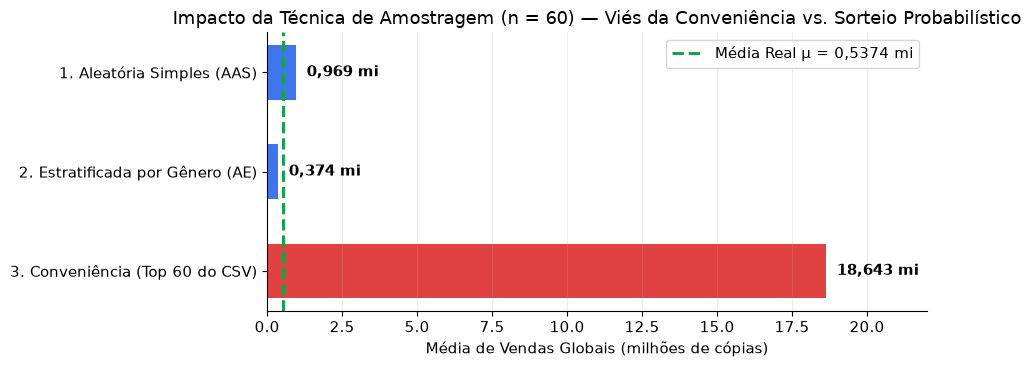

In [2]:
est.comparar_amostragens(df, coluna="Global_Sales", n=60, semente=42)


### 3. Intervalo de Confiança (95%) e Tamanho Mínimo da Amostra ($n$)
- **Correção de Bessel obrigatória (`ddof=1`):** $S(x)$ divide por $n - 1$ na amostra ($n = 50 > 30 \rightarrow$ usa **Normal $Z$**).
- **Tamanho Mínimo da Amostra:** para erro máximo $\varepsilon = 0,15\text{ mi}$ e $95\%$ de confiança, arredonda-se **sempre para cima** (`math.ceil`).


In [3]:
amostra_ic = df["Global_Sales"].sample(n=50, random_state=42)

est.calcular_intervalo_confianca(amostra_ic, confianca=0.95, mu_real=mu_pop)
est.calcular_tamanho_amostra(sigma_x=sigma_pop, erro_max=0.15, confianca=0.95)



### 📏 Intervalo de Confiança (95%) — Amostra $n = 50$
- **Relação Fundamental:** $\text{Confiança } (95\%) + \alpha (5\%) = 100\%$
- **Estimadores Amostrais (Correção de Bessel `ddof=1`):** $\bar{x} = 0{,}5084\text{ mi}$, $\quad S(x) = \sqrt{\frac{\sum (x_i - \bar{x})^2}{n - 1}} = 0{,}8610\text{ mi}$
- **Fluxograma:** σ(x) desconhecido e $n = 50 > 30$ → aproxima $S(x) \to \sigma(x)$ e usa **Distribuição Normal ($Z$)**.
- **Tabela $Z$ Unicaudal:** $P(0 \le z_0 \le Z_{\alpha/2}) = 0{,}5 - \frac{\alpha}{2} = 0{,}5 - 0{,}0250 = \mathbf{0{,}4750} \implies Z_{\alpha/2} = 1{,}9600$
- **Margem de Erro ($\varepsilon$) e Intervalo ($\bar{x} \pm \varepsilon$):**
  $$\varepsilon = Z_{\alpha/2} \cdot \frac{S(x)}{\sqrt{n}} = 1{,}9600 \cdot \frac{0{,}8610}{\sqrt{50}} = 1{,}9600 \cdot 0{,}1218 = \mathbf{0{,}2386\text{ mi}}$$
  $$\bar{x} - \varepsilon \le \mu \le \bar{x} + \varepsilon \implies \mathbf{0{,}2698 \le \mu \le 0{,}7470} \text{ (mi)}$$
- **Conferência ($\mu = 0{,}5374\text{ mi}$):** ✅ **SIM! O IC capturou a média populacional real** ($0{,}2698 \le 0{,}5374 \le 0{,}7470$).



### 🎯 Tamanho Mínimo da Amostra ($n$) para $\varepsilon = 0{,}15\text{ mi}$ (95% de confiança)
- **Tabela $Z$ Unicaudal:** $0{,}5 - \alpha/2 = 0{,}4750 \implies Z_{\alpha/2} = 1{,}9600 \quad | \quad \sigma(x) = 1{,}5550\text{ mi}$
  $$n = \left( Z_{\alpha/2} \cdot \frac{\sigma(x)}{\varepsilon} \right)^2 = \left( 1{,}9600 \cdot \frac{1{,}5550}{0{,}15} \right)^2 = 412{,}8230 \xrightarrow{\texttt{math.ceil}} \mathbf{n = 413\text{ jogos}}$$


---
## 👤 PARTE 2 — Apresentador 2: "Mitos Gamer" no Teste de Hipóteses
- **Regra do Fluxograma:** $\sigma(x)$ desconhecido com $n > 30 \rightarrow$ **Normal ($Z$)** | com $n \le 30 \rightarrow$ **$t\text{-Student}$ ($gl = n - 1$)**.
- **Critério Oficial de Decisão:** pertinência de $Z_{calc}$ / $t_{calc}$ à **Região Crítica ($R_c$)** ou **Não Crítica ($R_{NC}$)** ($\alpha = 5\%$).

### 4. Mito 1 — *"Jogos da Nintendo vendem acima da média global ($\mu_0 = 0,5374\text{ mi}$)?"*
- Teste **Unilateral à Direita** | $n = 40 > 30$ ($\sigma$ desconhecido $\rightarrow$ **Normal $Z$**).



### 🧪 Mito 1: Nintendo > Média Global (Unilateral à Direita, n = 40)
1. **Hipóteses:** $H_0: \mu \le 0{,}5374 \quad \text{vs.} \quad H_a: \mu > 0{,}5374 \quad (\text{Unilateral à Direita, }\alpha = 0{,}0500)$
2. **Amostra e Modelo ($1 - \alpha = 95\%$):** $n = 40$, $\bar{x} = 1{,}4345\text{ mi}$, $S(x) = 1{,}8008\text{ mi}$ — σ(x) desconhecido e $n = 40 > 30$ → aproxima $S(x) \to \sigma(x)$ e usa **Distribuição Normal ($Z$)**.
3. **Valor Crítico e Regiões (Tabela $Z$ Unicaudal ($0{,}5 - \alpha = 0{,}4500$)):** $Z_c = 1{,}6449 \;\; \Rightarrow \;\; R_c = [+1{,}6449;\,+\infty) \;\; | \;\; R_{NC} = (-\infty;\,+1{,}6449)$
4. **Estatística Calculada:**
   $$Z_{calc} = \frac{\bar{x} - \mu_0}{\frac{S(x)}{\sqrt{n}}} = \frac{1{,}4345 - 0{,}5374}{\frac{1{,}8008}{\sqrt{40}}} = \frac{0{,}8971}{0{,}2847} = \mathbf{3{,}1505}$$
5. **Decisão Formal (Região Crítica):** $$Z_{calc} = 3{,}1505 \in R_c \implies \mathbf{REJEITAMOS\; H_0}$$
   *(Info complementar: $\text{p-valor} = 0{,}0008$ — decisão tomada exclusivamente por $R_c / R_{NC}$).*
6. **Interpretação:** ✅ **Conclusão:** MITO CONFIRMADO! Jogos publicados pela Nintendo vendem significativamente acima da média global.
   - ⚠️ **Risco associado:** **Erro Tipo I ($\alpha = 5,0\%$)** — rejeitar $H_0$ caso ela fosse verdadeira na população.


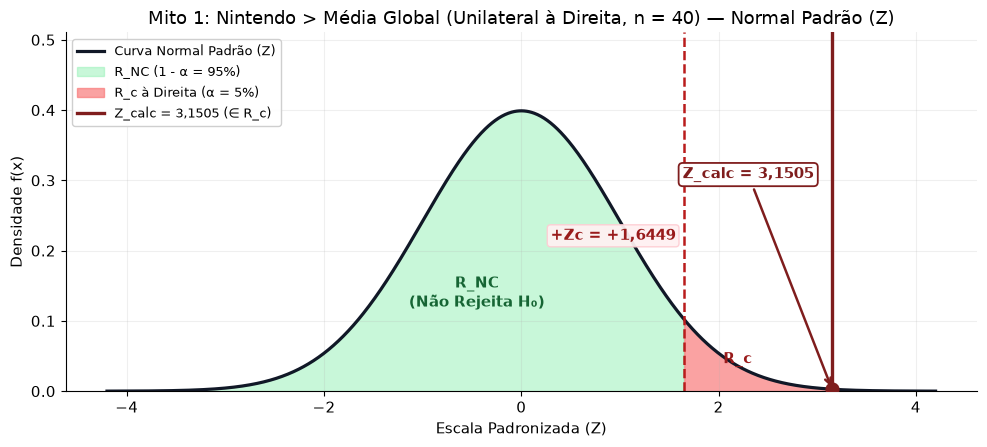

In [4]:
amostra_nintendo = df[df["Publisher"] == "Nintendo"]["Global_Sales"].sample(n=40, random_state=42)

est.testar_hipotese(
    amostra=amostra_nintendo,
    mu_0=mu_pop,
    alpha=0.05,
    tipo="direita",
    titulo="Mito 1: Nintendo > Média Global (Unilateral à Direita, n = 40)",
    veredito_rejeita="MITO CONFIRMADO! Jogos publicados pela Nintendo vendem significativamente acima da média global.",
)


### 5. Mito 2 — *"Jogos de PC (mídia física) vendem menos que a média global ($\mu_0 = 0,5374\text{ mi}$)?"*
- Teste **Unilateral à Esquerda** | Amostra pequena $n = 20 \le 30$ ($\sigma$ desconhecido $\rightarrow$ **$t\text{-Student}$ com $gl = 19$**, assumindo normalidade aproximada).
- 💡 *Contexto de mercado:* O dataset contabiliza **mídia física**, e o PC migrou cedo para distribuição digital (Steam).



### 🧪 Mito 2: PC (Mídia Física) < Média Global (Unilateral à Esquerda, n = 20)
1. **Hipóteses:** $H_0: \mu \ge 0{,}5374 \quad \text{vs.} \quad H_a: \mu < 0{,}5374 \quad (\text{Unilateral à Esquerda, }\alpha = 0{,}0500)$
2. **Amostra e Modelo ($1 - \alpha = 95\%$):** $n = 20$, $\bar{x} = 0{,}2345\text{ mi}$, $S(x) = 0{,}4799\text{ mi}$ — σ(x) desconhecido e $n = 20 \le 30$ → **Distribuição $t\text{-Student}$ ($t$)** com $S(x)$ (Bessel) e $gl = n - 1 = 19$.
3. **Valor Crítico e Regiões (Tabela $t\text{-Student}$ ($gl = 19$, cauda $= 0{,}0500$)):** $t_c = 1{,}7291 \;\; \Rightarrow \;\; R_c = (-\infty;\,-1{,}7291] \;\; | \;\; R_{NC} = (-1{,}7291;\,+\infty)$
4. **Estatística Calculada:**
   $$t_{calc} = \frac{\bar{x} - \mu_0}{\frac{S(x)}{\sqrt{n}}} = \frac{0{,}2345 - 0{,}5374}{\frac{0{,}4799}{\sqrt{20}}} = \frac{-0{,}3029}{0{,}1073} = \mathbf{-2{,}8228}$$
5. **Decisão Formal (Região Crítica):** $$t_{calc} = -2{,}8228 \in R_c \implies \mathbf{REJEITAMOS\; H_0}$$
   *(Info complementar: $\text{p-valor} = 0{,}0054$ — decisão tomada exclusivamente por $R_c / R_{NC}$).*
6. **Interpretação:** ✅ **Conclusão:** MITO CONFIRMADO! No varejo físico do dataset, jogos de PC têm média inferior à média global.
   - ⚠️ **Risco associado:** **Erro Tipo I ($\alpha = 5,0\%$)** — rejeitar $H_0$ caso ela fosse verdadeira na população.


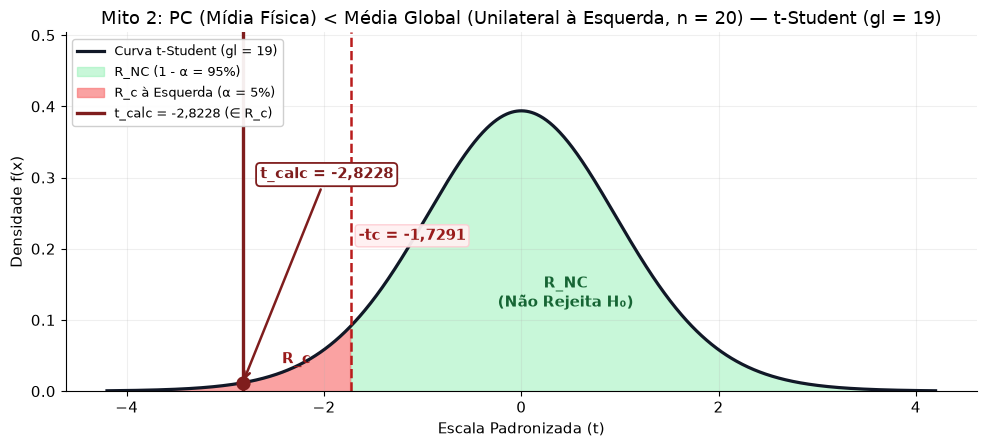

In [5]:
amostra_pc = df[df["Platform"] == "PC"]["Global_Sales"].sample(n=20, random_state=42)

est.testar_hipotese(
    amostra=amostra_pc,
    mu_0=mu_pop,
    alpha=0.05,
    tipo="esquerda",
    titulo="Mito 2: PC (Mídia Física) < Média Global (Unilateral à Esquerda, n = 20)",
    veredito_rejeita="MITO CONFIRMADO! No varejo físico do dataset, jogos de PC têm média inferior à média global.",
)


### 6. Mito 3 — *"A média de vendas do PlayStation 2 difere da média global ($\mu_0 = 0,5374\text{ mi}$)?"*
- Teste **Bilateral** | $n = 50 > 30$ (pelo **Teorema Central do Limite**, $\bar{x}$ tende à **Normal $Z$**, demonstrando $Z_{calc} \in R_{NC}$).
- 💡 *Volume total vs. média:* O PS2 tem $2.161$ jogos no CSV — grandes sucessos são diluídos por centenas de títulos menores.



### 🧪 Mito 3: PlayStation 2 ≠ Média Global (Bilateral, n = 50)
1. **Hipóteses:** $H_0: \mu = 0{,}5374 \quad \text{vs.} \quad H_a: \mu \neq 0{,}5374 \quad (\text{Bilateral, }\alpha/2 = 0{,}0250\text{ por cauda})$
2. **Amostra e Modelo ($1 - \alpha = 95\%$):** $n = 50$, $\bar{x} = 0{,}5160\text{ mi}$, $S(x) = 0{,}8034\text{ mi}$ — σ(x) desconhecido e $n = 50 > 30$ → aproxima $S(x) \to \sigma(x)$ e usa **Distribuição Normal ($Z$)**.
3. **Valor Crítico e Regiões (Tabela $Z$ Unicaudal ($0{,}5 - \alpha/2 = 0{,}4750$)):** $Z_c = 1{,}9600 \;\; \Rightarrow \;\; R_c = (-\infty;\,-1{,}9600] \cup [+1{,}9600;\,+\infty) \;\; | \;\; R_{NC} = (-1{,}9600;\,+1{,}9600)$
4. **Estatística Calculada:**
   $$Z_{calc} = \frac{\bar{x} - \mu_0}{\frac{S(x)}{\sqrt{n}}} = \frac{0{,}5160 - 0{,}5374}{\frac{0{,}8034}{\sqrt{50}}} = \frac{-0{,}0214}{0{,}1136} = \mathbf{-0{,}1887}$$
5. **Decisão Formal (Região Crítica):** $$Z_{calc} = -0{,}1887 \in R_{NC} \implies \mathbf{NÃO\; REJEITAMOS\; H_0}$$
   *(Info complementar: $\text{p-valor} = 0{,}8503$ — decisão tomada exclusivamente por $R_c / R_{NC}$).*
6. **Interpretação:** ⚖️ **Conclusão:** MITO REFUTADO! A média por jogo do PS2 acompanha o padrão médio global da indústria (Z_calc ∈ R_NC).
   - ⚠️ **Risco associado:** **Erro Tipo II ($\beta$)** — não rejeitar $H_0$ caso exista uma diferença real na população.


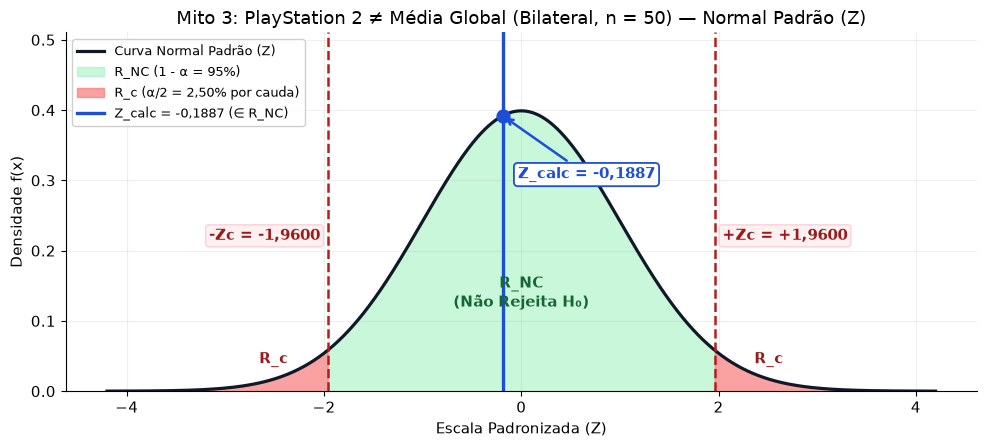

In [6]:
amostra_ps2 = df[df["Platform"] == "PS2"]["Global_Sales"].sample(n=50, random_state=42)

est.testar_hipotese(
    amostra=amostra_ps2,
    mu_0=mu_pop,
    alpha=0.05,
    tipo="bilateral",
    titulo="Mito 3: PlayStation 2 ≠ Média Global (Bilateral, n = 50)",
    veredito_nao_rejeita="MITO REFUTADO! A média por jogo do PS2 acompanha o padrão médio global da indústria (Z_calc ∈ R_NC).",
)


---
### 7. 🎤 Simulador "Ao Vivo" — Teste a sua Franquia ou Console!
- Altere qualquer parâmetro abaixo durante as perguntas da turma ou do professor e aperte `Shift + Enter` (ex.: `"Grand Theft Auto"`, `"Mario"`, `"FIFA"`, `"Call of Duty"`, `"Pokemon"`).


**🎮 Jogos sorteados na amostra (`Franquia='Grand Theft Auto'`, $n = 25$ de 28 disponíveis — exibindo 5 exemplos):**

,Name,Platform,Year,Genre,Publisher,Global_Sales
Rank,,,,,,
198,Grand Theft Auto V,XOne,2014,Action,Take-Two Interactive,5.08
10381,"Grand Theft Auto: Mission Pack #1, London 1969",PS,1998,Adventure,Take-Two Interactive,0.11
91,Grand Theft Auto: Liberty City Stories,PSP,2005,Action,Take-Two Interactive,7.72
2140,Grand Theft Auto: Vice City Stories,PS2,2007,Action,Take-Two Interactive,0.97
17,Grand Theft Auto V,PS3,2013,Action,Take-Two Interactive,21.40



### 🧪 Ao Vivo: Franquia='Grand Theft Auto' (n = 25)
1. **Hipóteses:** $H_0: \mu \le 0{,}5374 \quad \text{vs.} \quad H_a: \mu > 0{,}5374 \quad (\text{Unilateral à Direita, }\alpha = 0{,}0500)$
2. **Amostra e Modelo ($1 - \alpha = 95\%$):** $n = 25$, $\bar{x} = 5{,}8868\text{ mi}$, $S(x) = 6{,}8763\text{ mi}$ — σ(x) desconhecido e $n = 25 \le 30$ → **Distribuição $t\text{-Student}$ ($t$)** com $S(x)$ (Bessel) e $gl = n - 1 = 24$.
3. **Valor Crítico e Regiões (Tabela $t\text{-Student}$ ($gl = 24$, cauda $= 0{,}0500$)):** $t_c = 1{,}7109 \;\; \Rightarrow \;\; R_c = [+1{,}7109;\,+\infty) \;\; | \;\; R_{NC} = (-\infty;\,+1{,}7109)$
4. **Estatística Calculada:**
   $$t_{calc} = \frac{\bar{x} - \mu_0}{\frac{S(x)}{\sqrt{n}}} = \frac{5{,}8868 - 0{,}5374}{\frac{6{,}8763}{\sqrt{25}}} = \frac{5{,}3494}{1{,}3753} = \mathbf{3{,}8897}$$
5. **Decisão Formal (Região Crítica):** $$t_{calc} = 3{,}8897 \in R_c \implies \mathbf{REJEITAMOS\; H_0}$$
   *(Info complementar: $\text{p-valor} = 0{,}0003$ — decisão tomada exclusivamente por $R_c / R_{NC}$).*
6. **Interpretação:** ✅ **Conclusão:** Rejeitamos H₀! O recorte (Franquia='Grand Theft Auto') diverge significativamente de μ₀ = 0,5374 mi.
   - ⚠️ **Risco associado:** **Erro Tipo I ($\alpha = 5,0\%$)** — rejeitar $H_0$ caso ela fosse verdadeira na população.


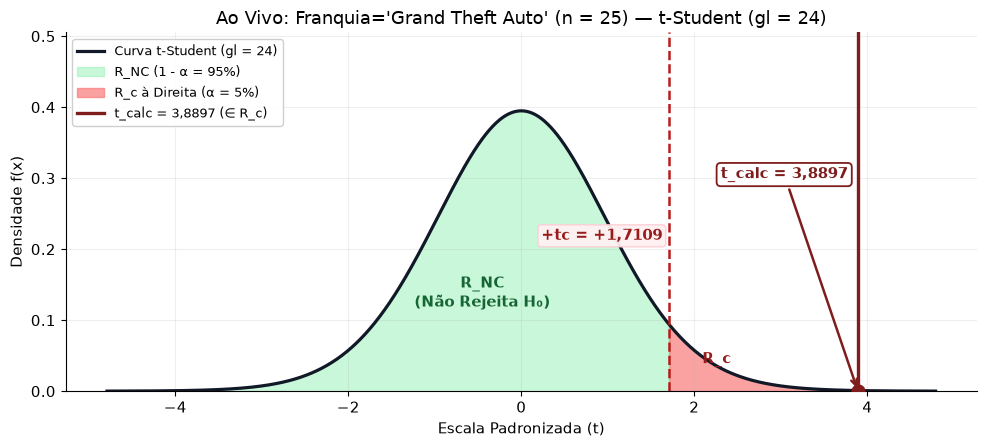

In [7]:
# ====== EDITE AQUI AO VIVO NA APRESENTAÇÃO ======
FRANQUIA    = "Grand Theft Auto"   # Ex.: "Mario", "FIFA", "Call of Duty", "Pokemon" ou None
PLATAFORMA  = None                 # Ex.: "X360", "Wii", "PS3", "DS" ou None
GENERO      = None                 # Ex.: "Shooter", "Sports", "Adventure", "Role-Playing" ou None
PUBLICADORA = None                 # Ex.: "Electronic Arts", "Activision", "Ubisoft" ou None

N_AMOSTRA   = 25                   # <= 30 usa t-Student; > 30 usa Normal Z
ALPHA       = 0.05                 # Nível de significância (ex.: 0.01, 0.05, 0.10)
TIPO_TESTE  = "direita"            # "direita", "esquerda" ou "bilateral"
MU_0        = mu_pop               # Média de referência (mu_pop = 0,5374 mi ou outro valor)
# ================================================

est.simular_ao_vivo(
    df,
    mu_0=MU_0,
    franquia=FRANQUIA,
    plataforma=PLATAFORMA,
    genero=GENERO,
    publicadora=PUBLICADORA,
    n=N_AMOSTRA,
    alpha=ALPHA,
    tipo=TIPO_TESTE,
)
